In [1]:
from pathlib import Path

from maite_datasets.object_detection import SkySeaLand

# Downloads to ./data/skysealand on first run (~262 MB), then writes the datamaite-format
# export beside it. A re-run reuses the export instead of rebuilding it.
SkySeaLand(root="./data", image_set="base", download=True, as_datamaite=True)

data_path = Path("./data/skysealand_datamaite_base")

/builds/jatic/aria/dataeval-flow/.nox/docs/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
from dataeval_flow import run_task
from dataeval_flow.config import (
    CocoDatasetConfig,
    PipelineConfig,
    SourceConfig,
    TaskConfig,
    ViewConfig,
    ViewOperation,
)
from dataeval_flow.config.extractors import BoVWExtractorConfig
from dataeval_flow.workflows.quality import (
    ClassOutliersSettings,
    DuplicatesSettings,
    ImageDuplicatesSettings,
    ImageOutliersSettings,
    OutliersSettings,
    QualityChecks,
    QualityConfig,
    TargetOutliersSettings,
)

workflow = QualityConfig(
    name="skysealand_cleaning",
    outliers=OutliersSettings(
        outlier_threshold=("adaptive", 3.5),  # Adaptive thresholding for outliers, bound 3.5
        flags=["dimension", "pixel", "visual"],  # All image stat groups
        cluster_threshold=3.5,  # Cluster-based detection in embedding space (requires extractor).
        cluster_algorithm="hdbscan",
        n_clusters=4,  # SkySeaLand has 4 classes
    ),
    duplicates=DuplicatesSettings(  # Duplicate detection: hash-based plus cluster-based.
        cluster_sensitivity=0.5,
        cluster_algorithm="hdbscan",
        n_clusters=4,
    ),
    checks=QualityChecks(
        image_duplicates=ImageDuplicatesSettings(
            exact=0.0,  # No exact duplicates allowed (default)
            near=5.0,  # Up to 5% near duplicates before warning (default)
        ),
        image_outliers=ImageOutliersSettings(
            warning=5.0  # Relaxed from 3% default for four collection sites and varied sensors
        ),
        target_outliers=TargetOutliersSettings(
            warning=10.0  # Relaxed from 3% default for annotation variance in object detection
        ),
        class_outliers=ClassOutliersSettings(
            warning=12.0  # Relaxed from 3% default for diverse class appearances
        ),
    ),
)

task = TaskConfig(
    name="skysealand_clean",
    workflow="skysealand_cleaning",
    sources="skysealand_src",
    extractor="bovw_ext",
)

# Build the pipeline configuration: datasets, sources, extractors, views, workflows, and tasks
config = PipelineConfig(
    max_processes=2,
    seed=0,
    datasets=[
        CocoDatasetConfig(name="skysealand_base", path=str(data_path)),
    ],
    views=[
        ViewConfig(
            name="sample300",
            operations=[
                ViewOperation(type="Shuffle", params={"seed": 0}),
                ViewOperation(type="Limit", params={"size": 300}),
            ],
        ),
    ],
    sources=[
        SourceConfig(name="skysealand_src", dataset="skysealand_base", view="sample300"),
    ],
    extractors=[
        BoVWExtractorConfig(name="bovw_ext", vocab_size=512, batch_size=32),
    ],
    workflows=[workflow],
    tasks=[task],
)

In [3]:
result = run_task(config, task, cache_dir=Path("./cache"))

/builds/jatic/aria/dataeval-flow/.nox/docs/lib/python3.13/site-packages/dataeval/_embeddings.py:566: UserWarning: BoVWExtractor is fitting its vocabulary on the data of this one call. Inside Embeddings, Duplicates or Outliers that call is a single batch of batch_size images, not the whole dataset, and every later batch is encoded with that vocabulary. Call fit() on the images you want the vocabulary learned from, then pass the fitted extractor. This warning is not raised once the extractor is fitted.
  embeddings = self._rows(self._extractor(batch_images), len(batch_idx))


OpenBLAS Warning : Detect OpenMP Loop and this application may hang. Please rebuild the library with USE_OPENMP=1 option.
OpenBLAS Warning : Detect OpenMP Loop and this application may hang. Please rebuild the library with USE_OPENMP=1 option.
OpenBLAS Warning : Detect OpenMP Loop and this application may hang. Please rebuild the library with USE_OPENMP=1 option.
OpenBLAS Warning : Detect OpenMP Loop and this application may hang. Please rebuild the library with USE_OPENMP=1 option.
OpenBLAS Warning : Detect OpenMP Loop and this application may hang. Please rebuild the library with USE_OPENMP=1 option.
OpenBLAS Warning : Detect OpenMP Loop and this application may hang. Please rebuild the library with USE_OPENMP=1 option.
OpenBLAS Warning : Detect OpenMP Loop and this application may hang. Please rebuild the library with USE_OPENMP=1 option.
OpenBLAS Warning : Detect OpenMP Loop and this application may hang. Please rebuild the library with USE_OPENMP=1 option.
OpenBLAS Warning : Detec

/builds/jatic/aria/dataeval-flow/src/dataeval_flow/_cache.py:1447: UserWarning: `file_name`, `file_path`, `label_file` and `original_id` were dropped: nearly every row holds a different value, so the column identifies rows rather than grouping them, and it is not numeric so there is no order along which to cut it into groups. Map the values onto a smaller vocabulary to keep the factor. See Metadata.dropped_factors.
  metadata.save(path)
/builds/jatic/aria/dataeval-flow/src/dataeval_flow/_cache.py:273: UserWarning: `height`, `num_annotations` and `width` were binned automatically ('uniform_width') because no bins were declared. The bin count is derived from the data, so it is not stable across samples and the same factor measured twice may not be comparable. Declare cutoffs with continuous_factor_bins={"height": [...]} to control this.
  export(path)


In [4]:
print(result.report())


  QUALITY
  Workflow:  skysealand_cleaning (quality)
  Timestamp: 2026-11-14T08:36:08.709415+00:00
  Duration:  137.99s
  Source:    skysealand_src (skysealand_base[sample300])
  Model:     bovw_ext (bovw)

  Steps: 9 ran

  SUMMARY
  Image Outliers ...................................... 27 images (9.0%)  [!!]
  Target Outliers ................................... 368 targets (8.4%)  [..]
  Class Outliers ........... worst: ship (20.6%), 1/4 classes over 12.0%  [..]

  Health: 1 warning(s) [!!] — review flagged findings

  IMAGE OUTLIERS                                                27 images (9.0%)
  From Outliers
    Item  Flags  Flagged by
    ----  -----  ------------------------------
    2         1  aspect_ratio -0.2447 < -0.2095
    14        1  zeros 0.01627 > 0.01488
    40        2  kurtosis 14.23 > 11.6
                 zeros 0.04301 > 0.01488
    56        1  aspect_ratio 0.9387 > 0.8134
    66        1  aspect_ratio -0.8901 < -0.2095
    67        1  aspect_ratio -0.2523

In [5]:
# The page styles its whole document, so the docs show it in an iframe of its own.
import html

from IPython.display import display


def show(page: str, height: int = 560) -> None:
    """*page* in an iframe, so its stylesheet and script stay inside it."""
    frame = (
        f'<iframe srcdoc="{html.escape(page, quote=True)}" title="HTML report" loading="lazy" '
        f'style="width:100%;height:{height}px;border:1px solid #d1d9e0;border-radius:6px"></iframe>'
    )
    display({"text/html": frame}, raw=True)

<iframe srcdoc="<!doctype html>
<html lang="en">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>Quality — skysealand_cleaning</title>
<style>:root { color-scheme: light dark;
 --bg: #ffffff; --card: #ffffff; --soft: #f6f8fa; --ink: #111827; --muted: #6b7280; --rule: #e5e7eb;
 --link: #1d4ed8; --ok: #16a34a; --info: #2563eb; --warning: #d97706; --mark: #dc2626;
 --s0: #2563eb; --s1: #d97706; --s2: #7c3aed; --s3: #16a34a;
 --tag: #eef2ff; --tag-ink: #1e1b4b;
}
@media (prefers-color-scheme: dark) { :root {
 --bg: #0f1115; --card: #171a21; --soft: #1d212a; --ink: #e5e7eb; --muted: #9ca3af; --rule: #2a2f3a;
 --link: #93c5fd; --ok: #22c55e; --info: #60a5fa; --warning: #f59e0b; --mark: #f87171;
 --s0: #60a5fa; --s1: #f59e0b; --s2: #a78bfa; --s3: #22c55e;
 --tag: #232a3d; --tag-ink: #c7d2fe;
} }
body { margin: 0; color: var(--ink); background: var(--bg);
 font: 15px/1.5 system-ui, -apple-system, "Segoe UI", Roboto, "Helvetica Neue", Arial, sans-serif; }
main { max-width: 72rem; margin: 0 auto; padding: 1.5rem; }
a { color: var(--link); }
h1, h2, h3, h4 { margin: 1.25rem 0 0.5rem; line-height: 1.25; }
h1 { font-size: 1.6rem; } h2 { font-size: 1.2rem; } h3 { font-size: 1.05rem; } h4 { font-size: 0.95rem; }
nav.contents { border: 1px solid var(--rule); border-radius: 7px; padding: 0.25rem 1rem; margin-bottom: 1.5rem; }
nav.contents h2 { font-size: 1rem; margin: 0.5rem 0; }
.controls { display: flex; justify-content: flex-end; gap: 0.5rem; margin-bottom: 0.5rem; }
.controls button { font: inherit; font-size: 0.8rem; padding: 0.2rem 0.7rem; cursor: pointer;
 color: var(--ink); background: var(--soft); border: 1px solid var(--rule); border-radius: 4px; }
.report { margin-bottom: 2.5rem; }
.report-head { display: flex; align-items: baseline; gap: 0.75rem; flex-wrap: wrap;
 border-bottom: 2px solid var(--ink); padding-bottom: 0.3rem; }
.report-head h1 { margin: 0; }
dl.fields.provenance { display: grid; grid-template-columns: max-content 1fr; gap: 0.15rem 1rem;
 margin: 0.6rem 0 1.2rem; padding: 0.5rem 0.8rem; background: var(--soft); border-radius: 6px;
 color: var(--muted); font-size: 0.85rem; }
dl.provenance dt { font-weight: 600; color: var(--ink); }
dl.provenance dd { margin: 0; overflow-wrap: anywhere; }
section.section > h2 { border-bottom: 1px solid var(--rule); padding-bottom: 0.2rem; }
details.card, details.panel { background: var(--card); border: 1px solid var(--rule);
 border-left: 4px solid var(--info); border-radius: 7px; padding: 0.3rem 1rem 0.6rem; margin: 0.9rem 0; }
details.card.ok { border-left-color: var(--ok); } details.card.warning { border-left-color: var(--warning); }
details.panel { border-left-color: var(--rule); margin-top: 1.5rem; }
:is(details.card, details.panel) > summary { cursor: pointer; list-style: none; }
:is(details.card, details.panel) > summary::-webkit-details-marker { display: none; }
:is(details.card, details.panel) > summary h2 { display: inline; font-size: 1.1rem; margin: 0; }
:is(details.card, details.panel) > summary::before { content: "▸"; color: var(--muted); margin-right: 0.4rem; }
:is(details.card, details.panel)[open] > summary::before { content: "▾"; }
.brief { font-weight: normal; color: var(--muted); margin-left: 0.5rem; }
.badge { font-size: 0.72rem; font-weight: 700; letter-spacing: 0.02em; border-radius: 1rem; padding: 0.05rem 0.55rem;
 margin-left: 0.5rem; color: #fff; background: var(--info); vertical-align: middle; }
.badge.ok { background: var(--ok); } .badge.warning { background: var(--warning); }
.badge.failed { background: var(--mark); }
code, pre { font-family: ui-monospace, SFMono-Regular, Menlo, Consolas, "DejaVu Sans Mono", monospace; }
code { font-size: 0.9em; background: var(--soft); padding: 0 0.2em; border-radius: 3px; }
pre { background: var(--soft); padding: 0.75rem; overflow-x: auto; font-size: 0.85rem; }
pre code { background: none; padding: 0; }
table { border-collapse: collapse; margin: 0.5rem 0; font-size: 
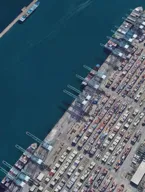
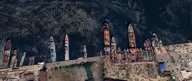
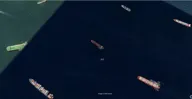
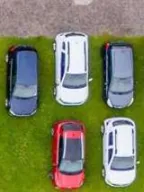
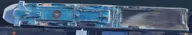
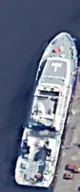
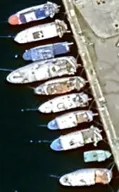
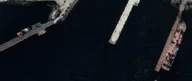
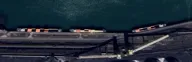
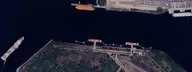
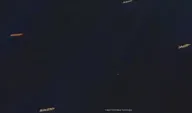
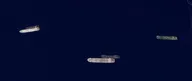
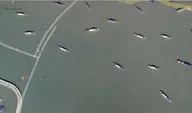
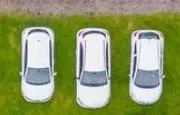
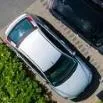
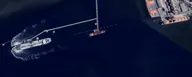
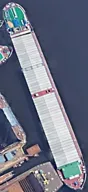
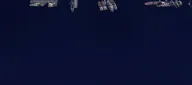
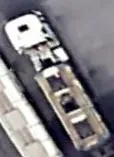
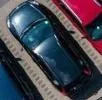
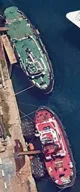
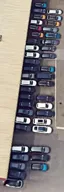
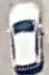
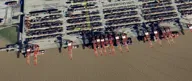
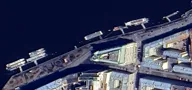
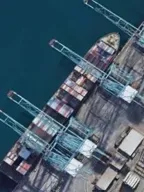
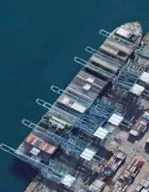
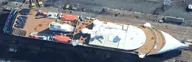
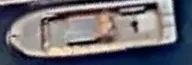
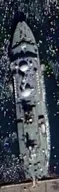
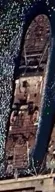
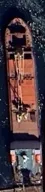
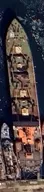
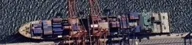
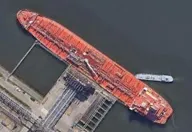
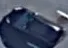
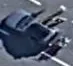
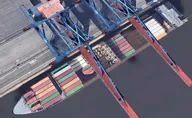
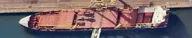
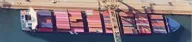
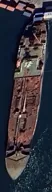
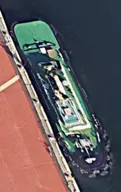
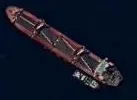
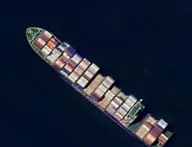
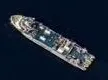
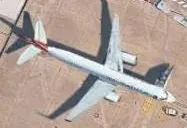
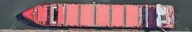
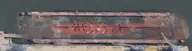
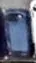
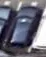
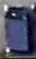
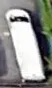
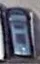
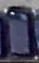
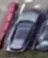
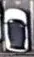
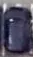
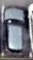
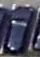
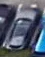
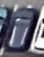
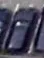
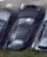
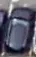
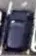
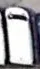
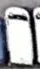
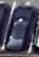
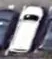
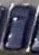
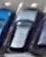
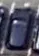
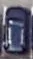
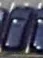
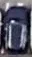
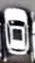
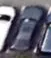
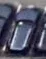
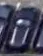
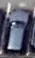
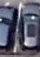
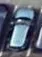
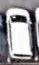
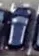
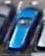
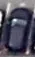
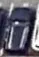
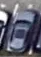
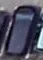
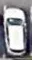
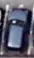
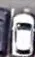
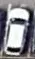
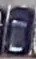
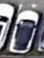
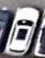
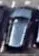
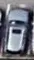
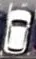
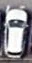
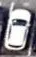
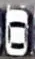
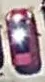
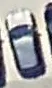
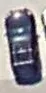
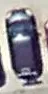
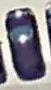
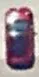
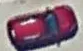
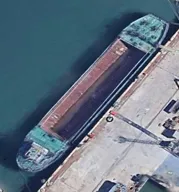
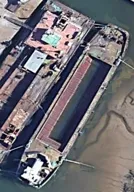
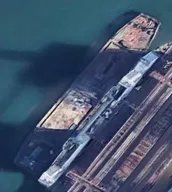
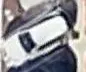
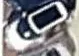
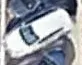
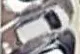
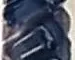
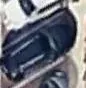
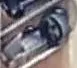
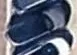
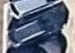
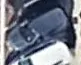
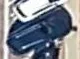
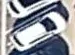
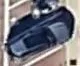
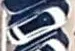
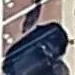
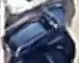
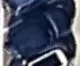
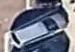
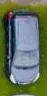
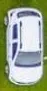
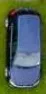
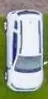
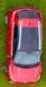
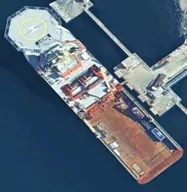
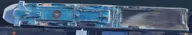
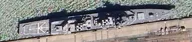
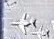
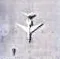
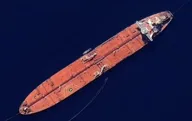
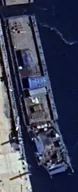
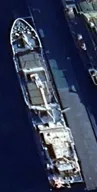
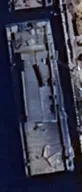
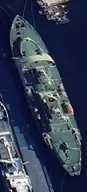
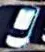
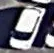
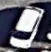
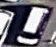
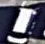
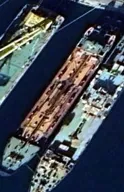
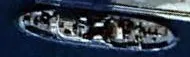
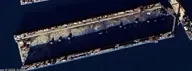
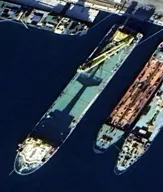
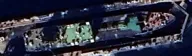
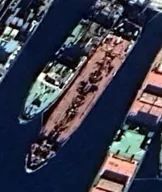
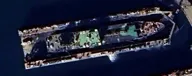
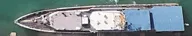
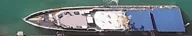
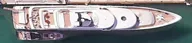
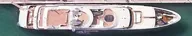
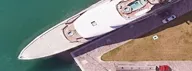
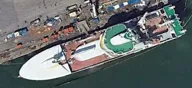
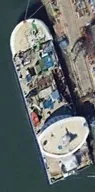
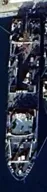
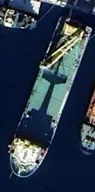
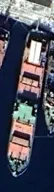
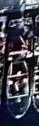
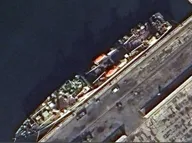
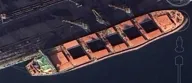
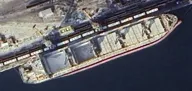
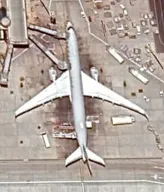
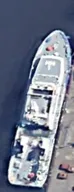
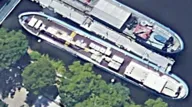
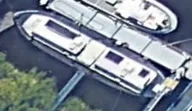
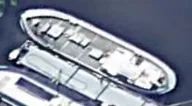
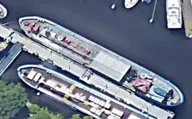
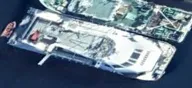
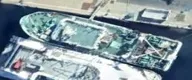
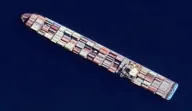
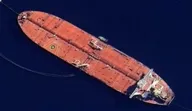
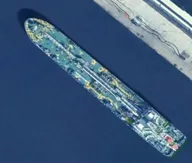
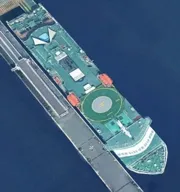
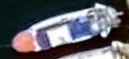
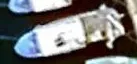
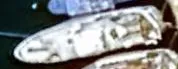
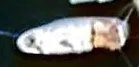
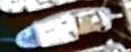

In [6]:
show(result.to_html())

In [7]:
print(list(result.steps))

['outliers', 'label-health', 'outliers-by-class', 'duplicates', 'image-outliers', 'target-outliers', 'class-outliers', 'image-duplicates', 'clean']


In [8]:
for finding in result.findings:
    print(f"{finding.severity:<8} {finding.title:<20} {finding.brief}")

warning  Image Outliers       27 images (9.0%)
info     Target Outliers      368 targets (8.4%)
info     Class Outliers       worst: ship (20.6%), 1/4 classes over 12.0%


In [9]:
ds = result.sources["skysealand_src"]

In [10]:
outliers = result.steps["outliers"].output
issues = outliers.data()

# Image-level flags name no box; the rest flag single boxes.
image_issues = issues.filter(issues["target_index"].is_null())
outlier_grouped: dict[int, list[str]] = {}
for row in image_issues.iter_rows(named=True):
    outlier_grouped.setdefault(row["item_index"], []).append(row["metric_name"])

outlier_indices = sorted(outlier_grouped)
print(f"Image outliers: {len(outlier_indices)} images flagged, {image_issues.height} total flags")

Image outliers: 27 images flagged, 33 total flags


Outlier sample: flagged metrics per image:
  Image     2: aspect_ratio
  Image    14: zeros
  Image    40: kurtosis, zeros
  Image    56: aspect_ratio
  Image    66: aspect_ratio
  Image    67: aspect_ratio
  Image    73: aspect_ratio
  Image   104: aspect_ratio
  Image   126: aspect_ratio, zeros


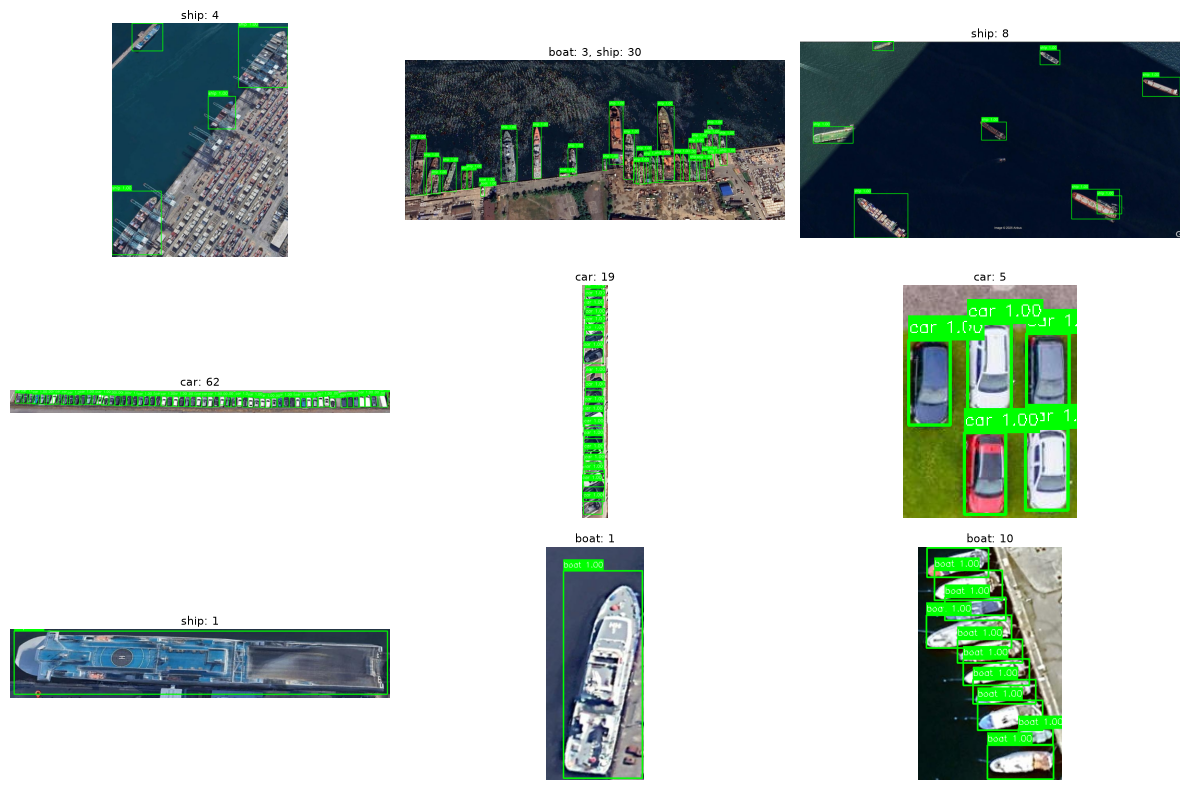

In [11]:
from dataeval_plots import plot

# Show a sample of outlier images (first 9)
if outlier_indices:
    sample = outlier_indices[:9]
    print("Outlier sample: flagged metrics per image:")
    for idx in sample:
        print(f"  Image {idx:>5d}: {', '.join(outlier_grouped[idx])}")
    _ = plot(ds, indices=sample, images_per_row=3, figsize=(12, 8), show_labels=True)

In [12]:
duplicates = result.steps["duplicates"].output.items
exact_groups = duplicates.exact
near_groups = duplicates.near

print(f"Exact duplicate groups: {len(exact_groups)}")
print(f"Near  duplicate groups: {len(near_groups)}")

Exact duplicate groups: 0
Near  duplicate groups: 0


In [13]:
# Plot exact duplicate groups (if any)
for i, indices in enumerate(exact_groups[:3]):
    print(f"\nExact group {i}: indices {indices}")
    _ = plot(ds, indices=indices, images_per_row=len(indices), figsize=(4 * len(indices), 4), show_labels=True)

In [14]:
# Plot near duplicate groups (if any)
for i, (indices, methods) in enumerate(near_groups[:3]):
    print(f"\nNear group {i}: indices {indices}  (methods: {methods})")
    _ = plot(ds, indices=indices, images_per_row=len(indices), figsize=(4 * len(indices), 4), show_labels=True)

In [15]:
clean = result.steps["clean"].output
print(f"Images before cleaning: {len(ds)}")
print(f"Images after cleaning:  {len(clean)}")
print(f"Removed: {result.steps['clean'].details['removed']}")

Images before cleaning: 300
Images after cleaning:  273
Removed: {'items': 27, 'detections': 368, 'tracks': 0, 'frames': 0}


In [16]:
json_str = result.export(fmt="json")
print(f"JSON output: {len(json_str)} characters")
print(json_str[:500] + "\n...")

JSON output: 1003531 characters
{
  "kind": "workflow",
  "metadata": {
    "version": "1.0",
    "timestamp": "2026-11-14T08:36:08.709415Z",
    "dataset_id": "skysealand_base",
    "label_source": "annotations",
    "model_id": "bovw_ext (bovw)",
    "preprocessor_id": null,
    "selection_id": "sample300",
    "source_descriptions": [
      "skysealand_src (skysealand_base[sample300])"
    ],
    "resolved_config": {
      "sources": [
        {
          "name": "skysealand_src",
          "dataset": "skysealand_base",
   
...
